# Email Spam Filtering with Naive Bayes

## 1. Download the dataset

In [1]:
!wget -O SpamEmailClassificationDataset.zip https://github.com/goitacademy/NUMERICAL-PROGRAMMING-IN-PYTHON/blob/main/SpamEmailClassificationDataset.zip?raw=true

Saving to: 'SpamEmailClassificationDataset.zip'


'SpamEmailClassificationDataset.zip' saved


## 2. Unzip the data

In [2]:
!unzip -o SpamEmailClassificationDataset.zip

Archive:  SpamEmailClassificationDataset.zip
  inflating: SpamEmailClassificationDataset/combined_data.csv  

## 3. Import the libraries

In [4]:
import re
from collections import Counter
from math import exp, log

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import BernoulliNB, MultinomialNB

nltk.download('stopwords')
nltk.download('punkt')
nltk.download('wordnet')
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/softjey/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /Users/softjey/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/softjey/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


## 4. Read the data

In [5]:
df = pd.read_csv('./SpamEmailClassificationDataset/combined_data.csv')
print(df.shape)
df.head()

(14861, 2)


,label,text
0,label,text
1,1,ounce feather bowl hummingbird opec moment ala...
2,1,wulvob get your medircations online qnb ikud v...
3,0,computer connection from cnn com wednesday es...
4,1,university degree obtain a prosperous future m...


In [6]:
df['label'].value_counts()

label
1        7813
0        7047
label       1
Name: count, dtype: int64

In [9]:
df = df.loc[df['label'] != 'label'].dropna().drop_duplicates(subset='text')
df['label'] = df['label'].astype(int)

print(df.shape)
df['label'].value_counts()

(14860, 2)


label
1    7813
0    7047
Name: count, dtype: int64

In [11]:
SAMPLE_PER_CLASS = 2500

full_counts = df['label'].map({0: 'Not Spam', 1: 'Spam'}).value_counts()
df = df.groupby('label').sample(n=SAMPLE_PER_CLASS, random_state=42).reset_index(drop=True)
print(df.shape)

(5000, 2)


## 5. Class distribution

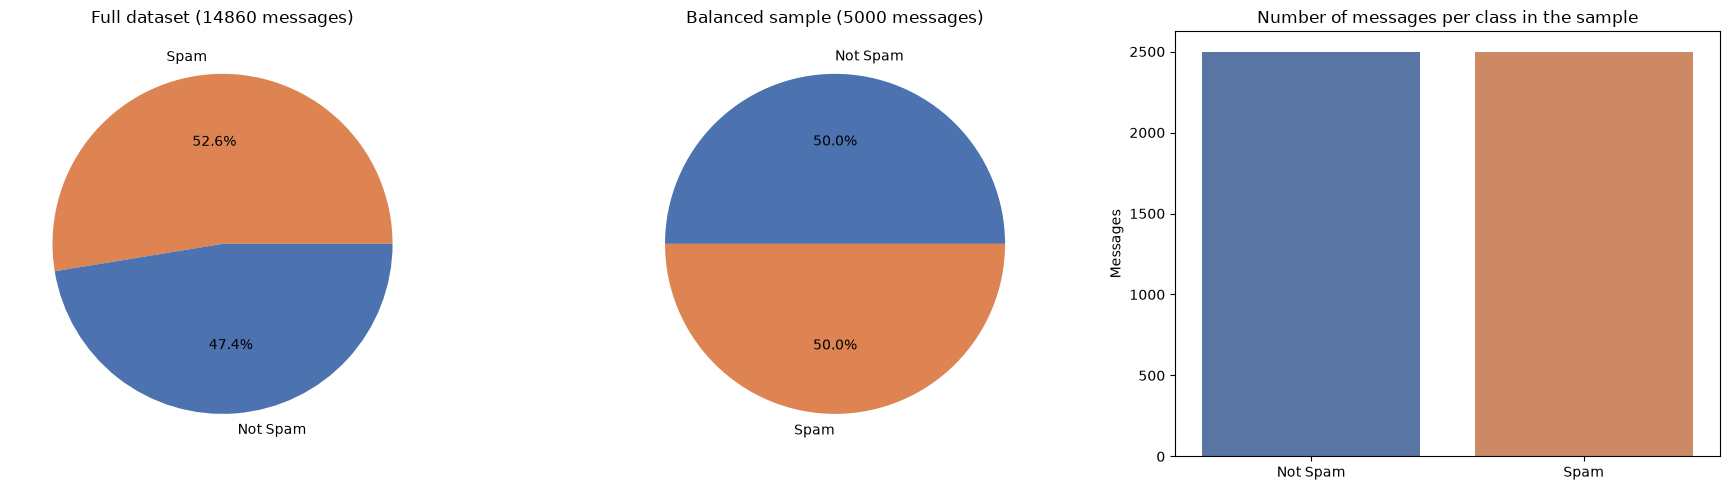

In [15]:
counts = df['label'].map({0: 'Not Spam', 1: 'Spam'}).value_counts()

colors = {'Not Spam': '#4c72b0', 'Spam': '#dd8452'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].pie(full_counts.to_numpy(), labels=full_counts.index.tolist(), autopct='%1.1f%%',
            colors=[colors[label] for label in full_counts.index])
axes[0].set_title(f'Full dataset ({full_counts.sum()} messages)')
axes[1].pie(counts.to_numpy(), labels=counts.index.tolist(), autopct='%1.1f%%',
            colors=[colors[label] for label in counts.index])
axes[1].set_title(f'Balanced sample ({counts.sum()} messages)')
sns.barplot(x=counts.index.tolist(), y=counts.to_numpy(), hue=counts.index.tolist(), palette=colors, ax=axes[2])
axes[2].set_title('Number of messages per class in the sample')
axes[2].set_ylabel('Messages')
plt.tight_layout()
plt.show()

## 6. Text preprocessing

In [20]:
corpus = []
lemmatizer = WordNetLemmatizer()

for document in df['text']:
  document = re.sub('[^a-zA-Z]', ' ', document).lower()
  words = document.split()
  words = [lemmatizer.lemmatize(word) for word in words if word not in stop_words]
  words = sorted(set(words))
  corpus.append(' '.join(words))

df['text'] = corpus
df = df.loc[df['text'].str.len() > 0].drop_duplicates(subset='text').reset_index(drop=True)

print(df.shape)
df.head()

(4922, 2)


,label,text
0,0,administrator advertise advertisement ago air ...
1,0,aarp able according action actor addition addr...
2,0,adequate already branch build claim code confi...
3,0,abuse adult aed aged aid airline also amanda a...
4,0,aborting ago appear append becker bug cc ch ch...


In [22]:
df['words'] = df['text'].str.split().str.len()
df.groupby('label')['words'].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
0,2426.0,106.815334,150.734440,1.0,44.0,73.0,118.00,2569.0
1,2496.0,79.692308,82.023594,1.0,28.0,53.0,102.25,927.0


## 7. Train and test data structures

In [25]:
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df['label'], random_state=42)
train_df = df.loc[train_idx]
test_df = df.loc[test_idx]

train_spam = train_df.loc[train_df['label'] == 1, 'text'].tolist()
train_ham = train_df.loc[train_df['label'] == 0, 'text'].tolist()
test_emails = {
  'spam': test_df.loc[test_df['label'] == 1, 'text'].tolist(),
  'ham': test_df.loc[test_df['label'] == 0, 'text'].tolist(),
}

print('train spam:', len(train_spam))
print('train ham:', len(train_ham))
print('test spam:', len(test_emails['spam']))
print('test ham:', len(test_emails['ham']))

train spam: 1996
train ham: 1941
test spam: 500
test ham: 485


## 8. Naive Bayes classifier

In [31]:
def word_document_counts(messages: list[str]) -> Counter[str]:
  counts: Counter[str] = Counter()
  for message in messages:
    counts.update(set(message.split()))

  return counts


def word_probabilities(counts: Counter[str], total: int, k: float = 1.0) -> dict[str, float]:
  return {word: (count + k) / (total + 2 * k) for word, count in counts.items()}


spam_counts = word_document_counts(train_spam)
ham_counts = word_document_counts(train_ham)
total_spam = len(train_spam)
total_ham = len(train_ham)

dict_spamicity = word_probabilities(spam_counts, total_spam)
dict_hamicity = word_probabilities(ham_counts, total_ham)
prob_spam = total_spam / (total_spam + total_ham)
prob_ham = total_ham / (total_spam + total_ham)

print('Unique words in spam:', len(dict_spamicity))
print('Unique words in ham:', len(dict_hamicity))
print(f'P(S) = {prob_spam:.4f}, P(H) = {prob_ham:.4f}')

Unique words in spam: 30740
Unique words in ham: 28029
P(S) = 0.5070, P(H) = 0.4930


In [35]:
def filter_words(email: str, vocab_spam: dict[str, float], vocab_ham: dict[str, float]) -> list[str]:
  return [word for word in email.split() if word in vocab_spam or word in vocab_ham]


def bayes(
  email: list[str],
  prob_spam: float,
  prob_ham: float,
  dict_spamicity: dict[str, float],
  dict_hamicity: dict[str, float],
  unseen_spam: float,
  unseen_ham: float,
) -> float:
  log_p_spam = log(prob_spam) + sum(log(dict_spamicity.get(word, unseen_spam)) for word in email)
  log_p_ham = log(prob_ham) + sum(log(dict_hamicity.get(word, unseen_ham)) for word in email)

  return 1 / (1 + exp(min(max(log_p_ham - log_p_spam, -700), 700)))


def spam_probability(email: str, k: float = 1.0) -> float:
  spamicity = dict_spamicity if k == 1.0 else word_probabilities(spam_counts, total_spam, k)
  hamicity = dict_hamicity if k == 1.0 else word_probabilities(ham_counts, total_ham, k)
  words = filter_words(email, spamicity, hamicity)

  return bayes(words, prob_spam, prob_ham, spamicity, hamicity, k / (total_spam + 2 * k), k / (total_ham + 2 * k))


def classify(email: str, k: float = 1.0) -> str:
  return 'spam' if spam_probability(email, k) >= 0.5 else 'ham'

In [37]:
for label in ['spam', 'ham']:
  example = test_emails[label][0]
  print(f'{label}: P(spam) = {spam_probability(example):.4f} -> {classify(example)} | {example[:90]}...')

spam: P(spam) = 0.0000 -> ham | add al alla ancora banged bene bisogno che ci cintura co colpa com come con corpo dalla da...
ham: P(spam) = 0.0000 -> ham | begin best christmas conversation could currently day desire discus discussion e everythin...


## 9. Classifier quality

In [40]:
def evaluate(test_emails: dict[str, list[str]], k: float = 1.0) -> tuple[list[int], list[int]]:
  y_true = []
  y_pred = []
  for label, messages in test_emails.items():
    for message in messages:
      y_true.append(int(label == 'spam'))
      y_pred.append(int(classify(message, k) == 'spam'))

  return y_true, y_pred


def quality(y_true: list[int], y_pred: list[int]) -> dict[str, float]:
  return {
    'accuracy': float(accuracy_score(y_true, y_pred)),
    'precision': float(precision_score(y_true, y_pred)),
    'recall': float(recall_score(y_true, y_pred)),
    'F1': float(f1_score(y_true, y_pred)),
  }


y_true, y_pred = evaluate(test_emails)
pd.Series(quality(y_true, y_pred)).round(4)

accuracy     0.8558
precision    0.9945
recall       0.7200
F1           0.8353
dtype: float64

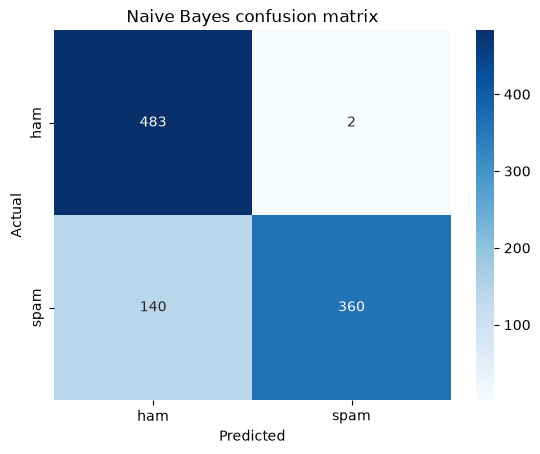

In [42]:
cm = confusion_matrix(y_true, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Naive Bayes confusion matrix')
plt.show()

In [49]:
smoothing_rows = []
for k in [0.01, 0.1, 0.5, 1.0, 2.0]:
  smoothing_rows.append({'k': k, **quality(*evaluate(test_emails, k))})

pd.DataFrame(smoothing_rows).set_index('k').round(4)

,accuracy,precision,recall,F1
k,,,,
0.01,0.8975,0.9950,0.802,0.8882
0.10,0.8802,0.9948,0.768,0.8668
0.50,0.8690,0.9947,0.746,0.8526
1.00,0.8558,0.9945,0.720,0.8353
2.00,0.8437,0.9943,0.696,0.8188


In [52]:
vectorizer = CountVectorizer(binary=True, token_pattern=r'\S+', lowercase=False)
X_train = vectorizer.fit_transform(train_spam + train_ham)
y_train = [1] * len(train_spam) + [0] * len(train_ham)
X_test = vectorizer.transform(test_emails['spam'] + test_emails['ham'])
y_test = [1] * len(test_emails['spam']) + [0] * len(test_emails['ham'])

comparison = {
  'lecture Naive Bayes (present words, k = 1)': quality(y_true, y_pred),
  'sklearn BernoulliNB (present + absent words)': quality(y_test, BernoulliNB(alpha=1.0).fit(X_train, y_train).predict(X_test).tolist()),
  'sklearn MultinomialNB (word counts)': quality(y_test, MultinomialNB(alpha=1.0).fit(X_train, y_train).predict(X_test).tolist()),
}
pd.DataFrame(comparison).T.round(4)

,accuracy,precision,recall,F1
"lecture Naive Bayes (present words, k = 1)",0.8558,0.9945,0.720,0.8353
sklearn BernoulliNB (present + absent words),0.8944,0.8587,0.948,0.9011
sklearn MultinomialNB (word counts),0.9360,0.9845,0.888,0.9338


In [56]:
test_df_lengths = pd.DataFrame({
  'words': [len(message.split()) for message in test_emails['spam'] + test_emails['ham']],
  'actual': ['spam'] * len(test_emails['spam']) + ['ham'] * len(test_emails['ham']),
  'predicted': ['spam' if label == 1 else 'ham' for label in y_pred],
})
test_df_lengths['length group'] = pd.cut(test_df_lengths['words'], bins=[0, 30, 60, 120, 10_000], labels=['<30', '30-60', '60-120', '>120'])
test_df_lengths['correct'] = test_df_lengths['actual'] == test_df_lengths['predicted']

test_df_lengths.pivot_table(index='length group', columns='actual', values='correct', aggfunc='mean', observed=False).round(3)

actual,ham,spam
length group,,
<30,0.986,0.736
30-60,0.992,0.780
60-120,1.000,0.722
>120,1.000,0.606


## 10. Words most likely to appear in spam

In [59]:
vocabulary = sorted(set(dict_spamicity) | set(dict_hamicity))
word_stats = pd.DataFrame({
  'word': vocabulary,
  'spam messages': [spam_counts[word] for word in vocabulary],
  'ham messages': [ham_counts[word] for word in vocabulary],
  'P(word | spam)': [dict_spamicity.get(word, 1 / (total_spam + 2)) for word in vocabulary],
  'P(word | ham)': [dict_hamicity.get(word, 1 / (total_ham + 2)) for word in vocabulary],
})
word_stats['spam / ham ratio'] = word_stats['P(word | spam)'] / word_stats['P(word | ham)']

top_spam = word_stats.sort_values('P(word | spam)', ascending=False).head(20)
top_spam.round(4)

,word,spam messages,ham messages,P(word | spam),P(word | ham),spam / ham ratio
14465,escapenumber,953,1044,0.4775,0.5378,0.8878
20460,http,770,926,0.3859,0.4771,0.8088
8086,com,582,490,0.2918,0.2527,1.1547
43834,u,503,395,0.2523,0.2038,1.2377
33454,price,486,142,0.2437,0.0736,3.3118
30214,one,468,519,0.2347,0.2676,0.8771
42702,time,434,468,0.2177,0.2414,0.9020
10405,day,408,292,0.2047,0.1508,1.3575
17950,get,400,492,0.2007,0.2537,0.7910
14464,escapelong,366,242,0.1837,0.1251,1.4687


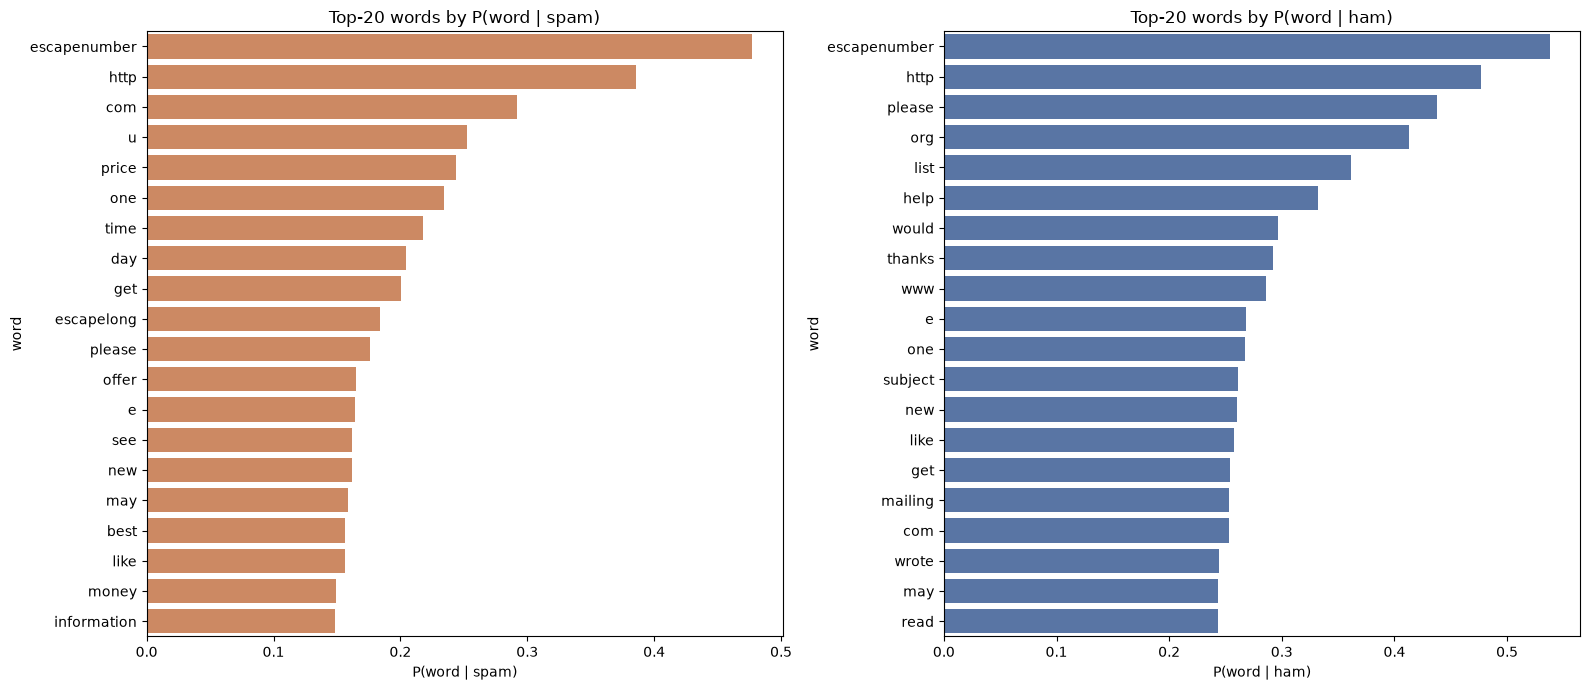

In [63]:
top_ham = word_stats.sort_values('P(word | ham)', ascending=False).head(20)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(data=top_spam, x='P(word | spam)', y='word', color='#dd8452', ax=axes[0])
axes[0].set_title('Top-20 words by P(word | spam)')
sns.barplot(data=top_ham, x='P(word | ham)', y='word', color='#4c72b0', ax=axes[1])
axes[1].set_title('Top-20 words by P(word | ham)')
plt.tight_layout()
plt.show()

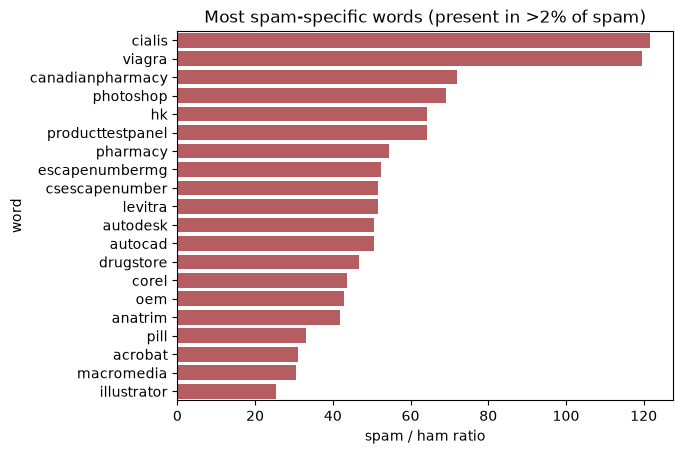

,word,spam messages,ham messages,P(word | spam),P(word | ham),spam / ham ratio
7358,cialis,124,0,0.0626,0.0005,121.5591
45374,viagra,122,0,0.0616,0.0005,119.6141
6136,canadianpharmacy,73,0,0.0370,0.0005,71.9630
32180,photoshop,70,0,0.0355,0.0005,69.0455
20022,hk,197,2,0.0991,0.0015,64.1832
33655,producttestpanel,65,0,0.0330,0.0005,64.1832
32084,pharmacy,111,1,0.0561,0.0010,54.4585
14656,escapenumbermg,53,0,0.0270,0.0005,52.5135
9810,csescapenumber,52,0,0.0265,0.0005,51.5410
24791,levitra,52,0,0.0265,0.0005,51.5410


In [69]:
frequent_spam_words = word_stats.loc[word_stats['P(word | spam)'] > 0.02]
frequent_spam_words = frequent_spam_words.sort_values('spam / ham ratio', ascending=False).head(20)

sns.barplot(data=frequent_spam_words, x='spam / ham ratio', y='word', color='#c44e52')
plt.title('Most spam-specific words (present in >2% of spam)')
plt.show()

frequent_spam_words.round(4)

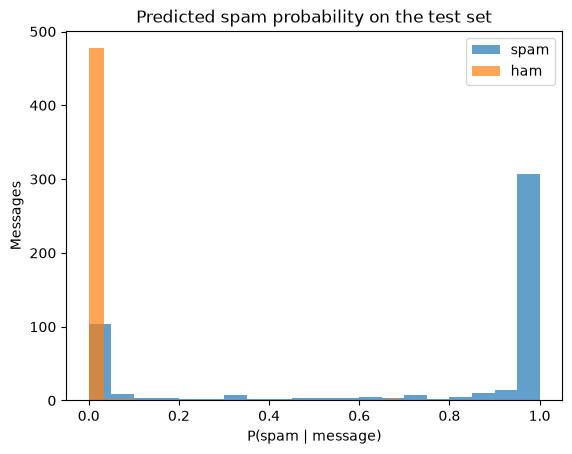

In [71]:
test_probabilities = np.array([spam_probability(message) for message in test_emails['spam'] + test_emails['ham']])
test_labels = np.array(y_test)

plt.hist(test_probabilities[test_labels == 1], bins=20, alpha=0.7, label='spam')
plt.hist(test_probabilities[test_labels == 0], bins=20, alpha=0.7, label='ham')
plt.xlabel('P(spam | message)')
plt.ylabel('Messages')
plt.title('Predicted spam probability on the test set')
plt.legend()
plt.show()

## Conclusion

- The provided file has 14,860 labelled emails (52.6% spam, 47.4% ham) plus a duplicated header row, which was dropped; a balanced sample of 2,500 emails per class was used.
- After lowercasing, stop-word removal, lemmatization and removing repeated words, 4,922 unique emails remained, split 80/20 into train_spam, train_ham and test_emails.
- The Naive Bayes classifier from the lecture (spamicity/hamicity = (n + 1) / (N + 2) per word, product over the words of the email in log space) reaches 85.6% accuracy, 99.5% precision, 72.0% recall and F1 = 0.835.
- The classifier almost never flags a normal email as spam (2 of 485 test ham emails), but misses 28% of spam; misses grow with message length (recall 74-78% for short spam, 61% for spam longer than 120 words), because every extra word multiplies in another small probability and ham messages are longer on average.
- Weaker smoothing helps: k = 0.01 raises accuracy to 89.8% and F1 to 0.888 with the same 99.5% precision.
- The lecture model uses only the words present in an email. BernoulliNB, which also counts absent words, catches more spam (recall 94.8%) at the cost of precision (85.9%); MultinomialNB gives the best balance here (accuracy 93.6%, F1 = 0.934).
- The words with the highest P(word | spam) are frequent generic tokens (escapenumber, http, com, price, offer, money), many of which are just as common in ham, so they carry little evidence.
- The most spam-specific words are pharmacy and pirated-software terms: cialis, viagra, canadianpharmacy, pharmacy, pill, levitra, photoshop, autocad, oem - they appear in spam 25-120 times more often than in ham.